# Experiment 6: Implementation of LSTM for Sentiment Analysis

**Saravanan P**

**24BAD105**



In [3]:
# 1. Import libraries and set random seeds
import re
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

MAX_WORDS = 10000   # Vocabulary limit
MAX_LEN = 200       # Fixed number of tokens per review
EMBEDDING_DIM = 64
BATCH_SIZE = 128
EPOCHS = 5

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


In [4]:
# 2. Load and explore the IMDB movie-review dataset
# Labels: 0 = Negative, 1 = Positive
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=MAX_WORDS)
word_index = imdb.get_word_index()
reverse_word_index = {index: word for word, index in word_index.items()}

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))
print("Training label counts [Negative, Positive]:", np.bincount(y_train))
print("Testing label counts [Negative, Positive]:", np.bincount(y_test))
print("Vocabulary size provided by IMDB:", len(word_index))

# Decode a few reviews for inspection. Encoded word IDs start at 3.
def decode_review(sequence):
    words = []
    for token_id in sequence:
        if token_id >= 3:
            words.append(reverse_word_index.get(token_id - 3, "?"))
    return " ".join(words)

for i in range(2):
    sentiment = "Positive" if y_train[i] == 1 else "Negative"
    print(f"\nSample review {i + 1} — {sentiment}:")
    print(decode_review(X_train[i])[:500])

print("\nNote: Keras supplies this dataset as integer-tokenized reviews. The original training reviews are already tokenized and encoded.")

Training reviews: 25000
Testing reviews: 25000
Training label counts [Negative, Positive]: [12500 12500]
Testing label counts [Negative, Positive]: [12500 12500]
Vocabulary size provided by IMDB: 88584

Sample review 1 — Positive:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to 

Sample review 2 — Negative:
big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and rid

In [5]:
# 3. Pad/truncate all reviews so every input has the same length
X_train_pad = pad_sequences(
    X_train, maxlen=MAX_LEN, padding="pre", truncating="pre"
)
X_test_pad = pad_sequences(
    X_test, maxlen=MAX_LEN, padding="pre", truncating="pre"
)

y_train = np.asarray(y_train).astype("float32")
y_test = np.asarray(y_test).astype("float32")

print("Padded training shape:", X_train_pad.shape)
print("Padded testing shape:", X_test_pad.shape)
print("Example padded sequence (last 30 IDs):", X_train_pad[0][-30:])

Padded training shape: (25000, 200)
Padded testing shape: (25000, 200)
Example padded sequence (last 30 IDs): [  18   51   36   28  224   92   25  104    4  226   65   16   38 1334
   88   12   16  283    5   16 4472  113  103   32   15   16 5345   19
  178   32]


In [6]:
# 4. Build and compile the LSTM model
model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM),
    LSTM(64, dropout=0.2),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# 5. Train the model; 20% of the training data is used for validation
history = model.fit(
    X_train_pad,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("\nFinal training accuracy:", round(history.history["accuracy"][-1], 4))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 4))
print("Final training loss:", round(history.history["loss"][-1], 4))
print("Final validation loss:", round(history.history["val_loss"][-1], 4))

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 56s 342ms/step - accuracy: 0.7524 - loss: 0.4854 - val_accuracy: 0.8596 - val_loss: 0.3393
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 47s 302ms/step - accuracy: 0.8974 - loss: 0.2626 - val_accuracy: 0.8614 - val_loss: 0.3237
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 47s 301ms/step - accuracy: 0.9227 - loss: 0.2149 - val_accuracy: 0.8556 - val_loss: 0.3345
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 49s 311ms/step - accuracy: 0.9244 - loss: 0.1985 - val_accuracy: 0.8552 - val_loss: 0.3455
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 80s 298ms/step - accuracy: 0.9370 - loss: 0.1693 - val_accuracy: 0.8732 - val_loss: 0.3464

Final training accuracy: 0.937
Final validation accuracy: 0.8732
Final training loss: 0.1693
Final validation loss: 0.3464


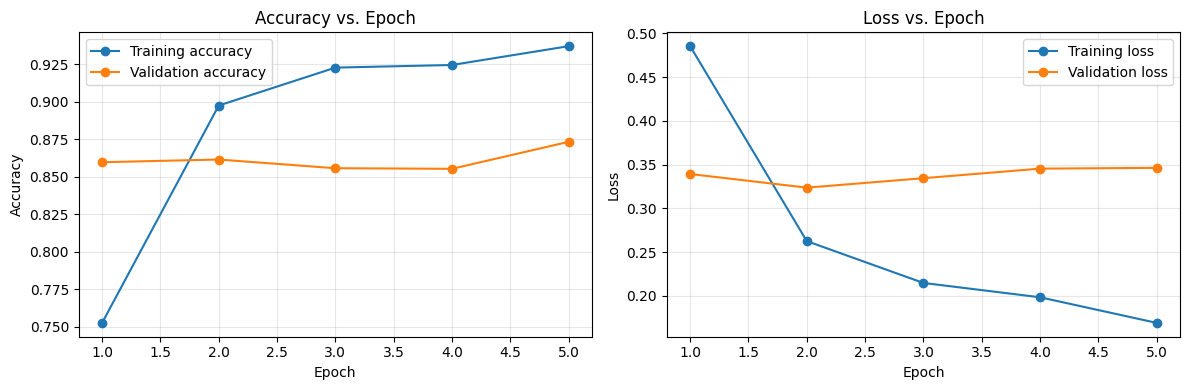

In [8]:
# 6. Plot accuracy and loss against training epochs
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy vs. Epoch")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], marker="o", label="Training loss")
plt.plot(epochs_range, history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss vs. Epoch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Test loss: 0.3668
Test accuracy: 0.8619
Accuracy: 0.8619
Precision: 0.8671
Recall: 0.8548
F1-score: 0.8609

Classification report:
              precision    recall  f1-score   support

    Negative       0.86      0.87      0.86     12500
    Positive       0.87      0.85      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



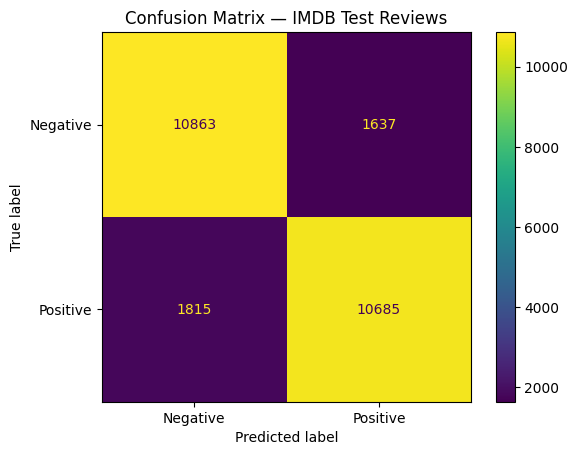

In [9]:
# 7. Evaluate on the separate test dataset
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=0)
test_probabilities = model.predict(X_test_pad, batch_size=BATCH_SIZE, verbose=0).ravel()
y_pred = (test_probabilities >= 0.5).astype(int)
y_true = y_test.astype(int)

print("Test loss:", round(float(test_loss), 4))
print("Test accuracy:", round(float(test_accuracy), 4))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, y_pred, zero_division=0), 4))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["Negative", "Positive"], zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
display = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Negative", "Positive"]
)
display.plot(values_format="d")
plt.title("Confusion Matrix — IMDB Test Reviews")
plt.show()

In [10]:
# 8. Predict sentiment for new review text using the same IMDB word index
def encode_new_review(text):
    # Clean text. IMDB reserves 1 for start and 2 for out-of-vocabulary words.
    cleaned_text = re.sub(r"[^a-zA-Z']", " ", text.lower())
    words = cleaned_text.split()
    sequence = [1]  # Start-of-review token

    for word in words:
        word_id = word_index.get(word)
        if word_id is None or word_id + 3 >= MAX_WORDS:
            sequence.append(2)  # Out-of-vocabulary token
        else:
            sequence.append(word_id + 3)

    return pad_sequences([sequence], maxlen=MAX_LEN, padding="pre", truncating="pre")


def predict_sentiment(review_text):
    padded_review = encode_new_review(review_text)
    probability = float(model.predict(padded_review, verbose=0)[0][0])
    sentiment = "Positive" if probability >= 0.5 else "Negative"
    return sentiment, probability

sample_reviews = [
    ("A wonderful film with excellent acting and a moving story.", "Positive"),
    ("The movie was boring, too long, and difficult to enjoy.", "Negative"),
    ("I loved every minute of this film; the performances were fantastic.", "Positive"),
    ("I hated this movie. The plot was confusing and the acting was terrible.", "Negative"),
]

for review, expected in sample_reviews:
    predicted, probability = predict_sentiment(review)
    print("\nReview:", review)
    print("Expected sentiment:", expected)
    print("Predicted sentiment:", predicted)
    print("Positive probability:", round(probability, 4))


Review: A wonderful film with excellent acting and a moving story.
Expected sentiment: Positive
Predicted sentiment: Positive
Positive probability: 0.9894

Review: The movie was boring, too long, and difficult to enjoy.
Expected sentiment: Negative
Predicted sentiment: Negative
Positive probability: 0.3334

Review: I loved every minute of this film; the performances were fantastic.
Expected sentiment: Positive
Predicted sentiment: Positive
Positive probability: 0.8845

Review: I hated this movie. The plot was confusing and the acting was terrible.
Expected sentiment: Negative
Predicted sentiment: Negative
Positive probability: 0.0149
